# Módulo 2 — Extracción de información: anuncios y promesas

**Proyecto:** Observatorio del discurso presidencial en español
**Unidades del temario:** EI 3.1 – 3.4 (concepto, expresiones regulares, autómatas, gramáticas
independientes del contexto, extracción de entidades y de eventos)

El objetivo es convertir **oraciones de discurso** en **eventos estructurados**:

| Campo | Ejemplo |
|---|---|
| `trigger` | "vamos a", "me comprometo a", "anuncio que", "entregaremos" |
| `action` | "construir un hospital" |
| `event_type` | `salud` |
| `frame.fecha` | "antes de diciembre de 2024" |
| `frame.monto` | "3,000 millones de pesos" |
| `frame.lugar` | "en Tijuana" |
| `frame.beneficiario` | "a los jóvenes" |
| `confidence` | 0.86 |

Restricciones del proyecto (fijas): **nada de aprendizaje profundo, transformadores ni
embeddings neuronales**. Todo aquí es simbólico, determinista y auditable:
autómata Aho-Corasick, expresiones regulares, una CFG con parser CYK y MinHash/LSH.

Pipeline por oración:

```
texto crudo ──► segmentación (punkt + offsets)
                 │
                 ├─► tokenización dual (cruda / plegada)
                 │
                 ├─► Aho-Corasick (disparadores + gazetteers)  ──► DFA de negación
                 ├─► regex de slots (fecha, monto, cantidad, %)
                 │
                 └─► chunker ──► CFG + CYK ──► plantilla de evento ──► dedup MinHash/LSH
```

La libreta va del caso pequeño al corpus completo: primero un discurso, después los
4,531 discursos y la evaluación contra el gold manual.

## 0. Preparación

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "ei_scripts").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from ei_scripts import config
from ei_scripts.automaton import AhoCorasick, NegationAutomaton, build_trigger_automaton, resolve_triggers
from ei_scripts.dedup import MinHasher, collision_probability, expected_error
from ei_scripts.extract import Options, automaton, extract_sentence
from ei_scripts.grammar import build_chunks, cyk, event_type, render_tree
from ei_scripts.segment import segment, tokenize
from ei_scripts.slots import extract_slots
from ri_scripts import load_index, search_bm25
from ri_scripts.corpus import read_doc

pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 90)
plt.rcParams["figure.figsize"] = (9, 3.5)

print("artefactos disponibles:")
for path in sorted(config.ARTIFACTS.glob("*")):
    print(f"  {path.name:24s} {path.stat().st_size / 1e6:7.2f} MB")

artefactos disponibles:
  eval.json                   0.01 MB
  events.jsonl               13.62 MB
  events_by_doc.jsonl        13.74 MB
  stats.json                  0.02 MB
  tables.md                   0.00 MB


## 1. Segmentación y tokenización con offsets

Se mantienen dos vistas del mismo texto, sincronizadas por offsets de carácter:

* **cruda** — para mostrar resultados y para los patrones que dependen de mayúsculas o acentos
  (`en Tijuana`, `antes de diciembre`, `3,000 millones`).
* **plegada** — minúsculas y sin acentos (`ri_scripts.preprocess.fold`), la que consume el
  autómata. `fold` **conserva la longitud**, así que el offset de un token es el mismo en las
  dos vistas.

Las oraciones salen de `punkt` para español; las transcripciones sin puntuación (mañaneras)
se parten además por `;`, `:` y `,` cuando superan `MAX_SENT_TOKENS = 90`.

In [2]:
by_doc = [json.loads(line) for line in open(config.EVENT_DOCS_JSONL, encoding="utf-8")]
doc_id = max(by_doc, key=lambda r: r["n"])["doc_id"]
doc = read_doc(doc_id)
print(f"doc_id={doc_id} · {doc['speaker']} · {doc['date']}")
print(f"título: {doc['title'][:110]}")
print(f"caracteres: {len(doc['text']):,}")

sents = segment(doc["text"])
print(f"oraciones: {len(sents):,} · media {np.mean([s.n_words for s in sents]):.1f} palabras")
for s in sents[:6]:
    print(f"[{s.idx:3d}] {s.start:6d}-{s.end:6d} ({s.n_words:3d} pal.) {s.text[:100]}")

doc_id=2769 · Pedro Sánchez · 2020-01-04
título: Discurso de investidura del candidato a la presidencia del Gobierno ante el Congreso de los Diputados
caracteres: 96,001
oraciones: 604 · media 25.4 palabras
[  0]      0-    70 (  9 pal.) Señora Presidenta, señorías, señoras y señores diputados, buenos días.
[  1]     72-    97 (  6 pal.) No se va a romper España.
[  2]     98-   132 (  7 pal.) No se va a romper la Constitución.
[  3]    133-   241 ( 18 pal.) Aquí lo que se va a romper es el bloqueo al Gobierno progresista democráticamente elegido por los es
[  4]    243-   462 ( 33 pal.) Señorías, comparezco ante este Congreso de los Diputados, en virtud del artículo 99 de nuestra Const
[  5]    464-   550 ( 13 pal.) Antes de exponer el programa de Gobierno, quiero hacer algunas reflexiones de partida.


In [3]:
tokens = tokenize(sents[0].text, sents[0].start)
pd.DataFrame([
    {"surface": t.surface, "folded": t.folded, "start": t.start, "end": t.end, "palabra": t.is_word}
    for t in tokens
]).head(14)

,surface,folded,start,end,palabra
0,Señora,señora,0,6,True
1,Presidenta,presidenta,7,17,True
2,",",",",17,18,False
3,señorías,señorias,19,27,True
4,",",",",27,28,False
5,señoras,señoras,29,36,True
6,y,y,37,38,True
7,señores,señores,39,46,True
8,diputados,diputados,47,56,True
9,",",",",56,57,False


## 2. Autómata Aho-Corasick: disparadores y gazetteers

Un autómata de patrones múltiples se define por tres funciones:

* `goto(q, a)` — transición de estado por símbolo (aquí, un **token plegado**),
* `fail(q)` — enlace de fallo: el sufijo propio más largo de la cadena del estado que también
  es prefijo de algún patrón,
* `out(q)` — patrones que terminan en `q`.

Búsqueda sobre una secuencia de `n` símbolos con `z` coincidencias: **O(n + z)**, sin importar
cuántos patrones haya. Es lo que permite barrer ~993 mil oraciones con ~480 patrones.

Primero un autómata mínimo, para ver las tres funciones sobre la mesa:

In [4]:
mini = AhoCorasick()
for seq, tag in [(("vamos", "a"), "futuro"), (("me", "comprometo", "a"), "compromiso"),
                 (("anuncio", "que"), "anuncio")]:
    mini.add_pattern(seq, tag=tag)
mini.build()

print("goto (q: {símbolo: estado}):")
for q, edges in enumerate(mini.goto):
    if edges:
        print(f"  q{q}: {edges}")
print("fail:", mini.fail)
print("out (q: [(patrón, longitud)]):", [(q, o) for q, o in enumerate(mini.out) if o])
k = min(mini.out)

goto (q: {símbolo: estado}):
  q0: {'vamos': 1, 'me': 3, 'anuncio': 6}
  q1: {'a': 2}
  q3: {'comprometo': 4}
  q4: {'a': 5}
  q6: {'que': 7}
fail: [0, 0, 0, 0, 0, 0, 0, 0]
out (q: [(patrón, longitud)]): [(2, [(0, 2)]), (5, [(1, 3)]), (7, [(2, 2)])]


In [5]:
# El autómata real: disparadores + futuros + lugares + organizaciones
ac = automaton()
print(ac.stats())
print()

from collections import Counter
clases = Counter(t[1] for t in ac.tags if t[0] == "trigger")
tipo = Counter(t[0] for t in ac.tags)
print("patrones por clase de disparador:", dict(clases))
print("patrones por tipo de léxico:    ", dict(tipo))
print()
print("ejemplos de patrones:", [" ".join(p) for p in ac.patterns[:6]])

{'estados': 727, 'patrones': 619, 'aristas': 726, 'alfabeto': 656, 'profundidad_max': 11}

patrones por clase de disparador: {'commit': 28, 'future_1p': 5, 'announce': 17, 'instruct': 8, 'goal': 7, 'deontic': 3, 'future_1p_syn': 194, 'future_3p_syn': 194}
patrones por tipo de léxico:     {'trigger': 456, 'place': 117, 'org': 46}

ejemplos de patrones: ['me comprometo', 'me comprometo a', 'nos comprometemos', 'nos comprometemos a', 'mi compromiso', 'mi compromiso es']


In [6]:
objetivo = next(s for s in sents if "vamos a" in s.text.lower())
words = [t for t in objetivo.tokens if t.is_word]
print(objetivo.text[:260], "\n")

matches = ac.scan([w.folded for w in words])
tabla = []
for m in matches:
    kind, clase, canon = ac.tags[m.pid]
    tabla.append({"tipo": kind, "patrón": " ".join(ac.patterns[m.pid]),
                  "span": f"{m.start}-{m.end}", "texto": " ".join(w.surface for w in words[m.start:m.end + 1])})
pd.DataFrame(tabla).head(12)

Con los resultados de las últimas elecciones, y una vez manifestada la posición de cada formación, no cabía otra mayoría parlamentaria que la que hoy vamos a presentar. 



,tipo,patrón,span,texto
0,trigger,vamos a,25-26,vamos a


## 3. DFA de negación

Una promesa negada no es una promesa (aunque a veces lo parezca). Se decide con un autómata
finito determinista de cuatro estados leído **hacia atrás** desde el disparador, con ventana de
`NEGATION_WINDOW = 6` palabras:

| estado | negador | puntuación fuerte | otro |
|---|---|---|---|
| limpio | negado | bloqueado | limpio |
| negado | doble | bloqueado | negado |
| doble | negado | bloqueado | doble |
| bloqueado | bloqueado | bloqueado | bloqueado |

"doble" equivale a limpio (la doble negación se cancela) y "bloqueado" cierra la ventana: un
punto o un `;` impide que un "no" de la oración anterior alcance al disparador.

In [7]:
neg = NegationAutomaton()
pruebas = [
    "Vamos a construir un hospital en Tijuana.",
    "No vamos a aumentar los impuestos.",
    "Nunca vamos a aumentar los impuestos.",
    "No es cierto que no vamos a construir el hospital.",
    "Quizá podríamos construir el hospital el próximo año.",
    "Vamos a construir el hospital. No vamos a cerrar escuelas.",
]
for txt in pruebas:
    toks = [t for t in tokenize(txt) if t.is_word]
    pos = next((i for i, t in enumerate(toks) if t.folded in {"vamos", "podriamos"}), 0)
    print(f"{txt:58s} -> {neg.polarity(toks, pos, txt):9s} (estado {neg.state_before(toks, pos, txt)})")

pd.DataFrame(neg.describe()).T

Vamos a construir un hospital en Tijuana.                  -> afirmado  (estado 0)
No vamos a aumentar los impuestos.                         -> negado    (estado 1)
Nunca vamos a aumentar los impuestos.                      -> negado    (estado 1)
No es cierto que no vamos a construir el hospital.         -> afirmado  (estado 2)
Quizá podríamos construir el hospital el próximo año.      -> atenuado  (estado 0)
Vamos a construir el hospital. No vamos a cerrar escuelas. -> afirmado  (estado 0)


,negador,puntuacion,otro
limpio,negado,bloqueado,limpio
negado,doble,bloqueado,negado
doble,negado,bloqueado,doble
bloqueado,bloqueado,bloqueado,bloqueado


## 4. Slots por expresiones regulares

Los slots son la parte cerrada del marco. Se buscan sobre texto **crudo** y cada patrón se
registra con su nombre (`evidence`) para poder auditar de dónde salió cada dato. Los valores se
normalizan: fechas a `AAAA-MM` o marcador relativo, montos y cantidades a número.

Un span sólo puede recibir un slot; gana el de mayor prioridad
`DATE > MONEY > PCT > QTY > PLACE > BENEF`.

In [8]:
from dataclasses import dataclass

@dataclass
class Oracion:
    text: str
    start: int = 0

ejemplos = [
    "Vamos a construir un hospital en Tijuana antes de diciembre de 2024, con 3,000 millones de pesos.",
    "Entregaremos 15 mil becas a los jóvenes en los próximos 100 días.",
    "Me comprometo a reducir la inflación en 35 por ciento y a pavimentar 120 kilómetros.",
    "Invertiremos 1,500 millones de dólares y 250 mdp en obra pública el próximo año.",
    "Vamos a apoyar a las madres trabajadoras de Nuevo León.",
]
filas = []
for txt in ejemplos:
    for s in extract_slots(Oracion(txt)):
        filas.append({"oración": txt[:52] + "…", "slot": s.kind, "texto": s.surface,
                      "valor": s.value, "evidencia": s.evidence})
pd.DataFrame(filas)

,oración,slot,texto,valor,evidencia
0,Vamos a construir un hospital en Tijuana antes de di…,PLACE,en Tijuana,Tijuana,lugar_mayuscula
1,Vamos a construir un hospital en Tijuana antes de di…,DATE,antes de diciembre,rel:antes de diciembre,rel
2,Vamos a construir un hospital en Tijuana antes de di…,DATE,2024,2024,abs
3,Vamos a construir un hospital en Tijuana antes de di…,MONEY,"3,000 millones de pesos",3000000000,moneda
4,Entregaremos 15 mil becas a los jóvenes en los próxi…,QTY,15 mil becas,15000,cantidad
5,Entregaremos 15 mil becas a los jóvenes en los próxi…,DATE,en los próximos 100 días,rel:en los próximos 100 días,rel
6,Me comprometo a reducir la inflación en 35 por cient…,PCT,35 por ciento,35%,porcentaje
7,Me comprometo a reducir la inflación en 35 por cient…,QTY,120 kilómetros,120,cantidad
8,"Invertiremos 1,500 millones de dólares y 250 mdp en …",MONEY,"1,500 millones de dólares",1500000000,moneda
9,"Invertiremos 1,500 millones de dólares y 250 mdp en …",MONEY,250 mdp,250 MDP,moneda_abbr


## 5. Chunker + gramática independiente del contexto + CYK

Parsear español completo con una CFG escrita a mano no es viable; parsear el **molde del evento**
sí. El chunker colapsa el léxico en etiquetas con papel semántico y la CFG decide si esas
etiquetas forman un marco válido. En forma binaria (CNF):

```
S    -> PRE S2 | S2
S2   -> TRIG REST | VTRIG MODS
REST -> ACC | ACC MODS | MODS ACC | MODS TAIL
TAIL -> ACC MODS
MODS -> MOD | MOD MODS
MOD  -> SN | LOC | ORG | BENEF | PLAZO | MONTO | MISC
PRE  -> SN | LOC | ORG | PLAZO | MONTO | MISC
```

`ACC` (verbo de acción) es **obligatorio**: sin acción no hay promesa. `VTRIG` cubre el caso en
que el propio disparador es el verbo ("Entregaremos…"). CYK sobre `n` chunks cuesta
O(n³·|P|); con n ≤ 40 son microsegundos.

In [9]:
casos = [
    "Vamos a construir un hospital en Tijuana antes de diciembre de 2024.",
    "Entregaremos 120 kilómetros de carretera el próximo año.",
    "Me comprometo a entregar 15 mil becas a los jóvenes en los próximos 100 días.",
    "Vamos a ver qué pasa con los diputados.",
    "Anuncio que vamos a construir la refinería en Dos Bocas.",
    "Nunca vamos a aumentar los impuestos.",
    "En Tijuana vamos a construir un hospital.",
]
for txt in casos:
    words = [t for t in tokenize(txt) if t.is_word]
    ms = ac.scan([w.folded for w in words])
    hits = resolve_triggers(ms, ac, words, txt)
    gaz = [("LOC", m.start, m.end) for m in ms if ac.tags[m.pid][0] == "place"]
    chunks = build_chunks(words, hits, extract_slots(Oracion(txt)), gaz)
    labels = [c.label for c in chunks]
    ok, tree = cyk(labels)
    print(f"{txt}\n  {labels}  →  CYK={ok}  tipo={event_type(chunks, words)}")
    print("  " + " | ".join(f"{c.label}:{c.text}" for c in chunks) + "\n")

Vamos a construir un hospital en Tijuana antes de diciembre de 2024.
  ['TRIG', 'ACC', 'LOC', 'PLAZO', 'MISC', 'PLAZO']  →  CYK=True  tipo=('salud', 'hospital')
  TRIG:Vamos a | ACC:construir un hospital | LOC:en Tijuana | PLAZO:antes de diciembre | MISC:de | PLAZO:2024

Entregaremos 120 kilómetros de carretera el próximo año.
  ['VTRIG', 'MONTO', 'SN', 'PLAZO']  →  CYK=True  tipo=('infraestructura', 'carretera')
  VTRIG:Entregaremos | MONTO:120 kilómetros | SN:de carretera | PLAZO:el próximo año

Me comprometo a entregar 15 mil becas a los jóvenes en los próximos 100 días.
  ['TRIG', 'ACC', 'MONTO', 'MISC', 'PLAZO']  →  CYK=True  tipo=('educacion', 'becas')
  TRIG:Me comprometo a | ACC:entregar | MONTO:15 mil becas | MISC:a los jóvenes | PLAZO:en los próximos 100 días

Vamos a ver qué pasa con los diputados.
  ['SN']  →  CYK=False  tipo=('politica_institucional', 'diputados')
  SN:Vamos a ver qué pasa con los diputados

Anuncio que vamos a construir la refinería en Dos Bocas.
  ['TRIG

In [10]:
# Árbol de un parse aceptado
words = [t for t in tokenize(casos[0]) if t.is_word]
ms = ac.scan([w.folded for w in words])
hits = resolve_triggers(ms, ac, words, casos[0])
gaz = [("LOC", m.start, m.end) for m in ms if ac.tags[m.pid][0] == "place"]
chunks = build_chunks(words, hits, extract_slots(Oracion(casos[0])), gaz)
ok, tree = cyk([c.label for c in chunks])
print(render_tree(tree))

S
  S2
    TRIG
    REST
      ACC
      MODS
        MOD
          LOC
        MODS
          MOD
            PLAZO
          MODS
            MOD
              MISC
            MODS
              MOD
                PLAZO


## 6. Plantilla de evento y score de confianza

Cada oración aceptada se convierte en un registro con doc_id, offsets, disparador, acción, tipo,
marco de slots, árbol de parse y confianza. El score es una suma ponderada de evidencias
normalizada por los pesos **activos**:

$$\text{conf} = \frac{\sum_i w_i\, e_i}{\sum_i w_i}\cdot\varphi(\text{polaridad})$$

con `w = (0.40 disparador, 0.20 acción, 0.15 slot, 0.15 CYK, 0.10 lugar)`, `e_i ∈ [0,1]`
(la acción vale 1.0 si es de *contenido* —construir, entregar— y 0.5 si es *de discurso*
—informar, presentar—) y `φ = 1 / 0.7 / NEGATION_FACTOR` según polaridad.

In [11]:
opts = Options()
filas = []
for txt in casos:
    sent = next(s for s in segment(txt))
    ev = extract_sentence(sent, opts, ac, {"doc_id": doc_id, "speaker": doc["speaker"], "date": doc["date"]})
    if ev is None:
        filas.append({"oración": txt[:70], "evento": "— rechazada —"})
        continue
    filas.append({
        "oración": txt[:60],
        "disparador": ev["trigger"],
        "acción": ev["action"][:28],
        "tipo": ev["event_type"],
        "confianza": ev["confidence"],
        "fecha": ev["frame"]["fecha"]["texto"] if ev["frame"]["fecha"] else None,
        "monto/cant.": (ev["frame"]["monto"] or ev["frame"]["cantidad"] or {}).get("texto"),
        "lugar": ev["frame"]["lugar"],
    })
pd.DataFrame(filas)

,oración,disparador,acción,tipo,confianza,fecha,monto/cant.,lugar,evento
0,Vamos a construir un hospital en Tijuana antes de diciembre,vamos a,construir un hospital,salud,0.96,antes de diciembre,NaN,en Tijuana,NaN
1,Entregaremos 120 kilómetros de carretera el próximo año.,entregaremos,Entregaremos,infraestructura,0.86,el próximo año,120 kilómetros,NaN,NaN
2,Me comprometo a entregar 15 mil becas a los jóvenes en los p,me comprometo a,entregar,educacion,0.90,en los próximos 100 días,15 mil becas,NaN,NaN
3,Vamos a ver qué pasa con los diputados.,NaN,NaN,NaN,NaN,NaN,NaN,NaN,— rechazada —
4,Anuncio que vamos a construir la refinería en Dos Bocas.,vamos a,construir la refinería,infraestructura,0.81,NaN,NaN,en Dos Bocas,NaN
5,Nunca vamos a aumentar los impuestos.,NaN,NaN,NaN,NaN,NaN,NaN,NaN,— rechazada —
6,En Tijuana vamos a construir un hospital.,vamos a,construir un hospital,salud,0.81,NaN,NaN,En Tijuana,NaN


In [12]:
# Un evento real del corpus, con todos sus campos y su árbol de parse
ev = next(
    json.loads(line) for line in open(config.EVENTS_JSONL, encoding="utf-8")
    if '"event_type": "infraestructura"' in line and '"monto": {' in line
)
print(json.dumps({k: ev[k] for k in ("speaker", "date", "trigger", "action", "event_type",
                                     "frame", "confidence", "polarity", "method")},
                 ensure_ascii=False, indent=2))
print()
print(ev["cyk_tree"])

{
  "speaker": "Andrés Manuel López Obrador",
  "date": "2021-07-21",
  "trigger": "anuncio",
  "action": "y que al final los únicos beneficiados de esta inversión serían los desarrolladores de este lugar",
  "event_type": "infraestructura",
  "frame": {
    "fecha": null,
    "monto": {
      "texto": "53 millones de pesos",
      "valor": "53000000"
    },
    "cantidad": null,
    "porcentaje": null,
    "lugar": null,
    "organizacion": null,
    "beneficiario": null
  },
  "confidence": 0.72,
  "polarity": "afirmado",
  "method": "ac+regex+cyk"
}

S
  PRE
    MISC
  S2
    TRIG
    REST
      MODS
        MOD
          SN
        MODS
          MOD
            MONTO
          MODS
            MOD
              MISC
            MODS
              MOD
                MONTO
      ACC


## 7. El corpus completo: embudo, volumen y distribuciones

`python -m ei_scripts.build_events` procesa los 4,531 discursos (~158 s) y escribe
`events.jsonl`, `events_by_doc.jsonl` y `stats.json`. El embudo muestra dónde se cae cada
oración: es la parte más útil para explicar el sistema.

In [13]:
stats = json.loads((config.ARTIFACTS / "stats.json").read_text(encoding="utf-8"))
print("opciones:", stats["opciones"])
print("volumen:", {k: v for k, v in stats["volumen"].items() if k != "autómata"})
print("autómata:", stats["volumen"]["autómata"])
pd.Series(stats["embudo"], name="oraciones").to_frame()

opciones: {'slots': True, 'cyk': True, 'negacion': True, 'gazetteer': True, 'min_conf': 0.55, 'limit': 0}
volumen: {'documentos': 4531, 'eventos': 11052, 'segundos': 145.5}
autómata: {'estados': 727, 'patrones': 619, 'aristas': 726, 'alfabeto': 656, 'profundidad_max': 11}


,oraciones
oraciones,993494
sin_disparador,756922
con_disparador,93532
rechazadas_pregunta,79588
rechazadas_cyk,73272
descartadas_cortas,60617
cyk_acepta,20260
aceptadas,11052
rechazadas_sin_accion,7532
rechazadas_cita,2835


In [14]:
tabla = pd.DataFrame(stats["por_hablante"]).T
tabla["tipos"] = tabla["tipos"].apply(lambda d: ", ".join(list(d)[:3]))
tabla

,eventos,oraciones,eventos_por_1000_oraciones,confianza_media,tipos
Andrés Manuel López Obrador,9265,789289,11.74,0.688,"otro, social, salud"
Pedro Sánchez,1077,127486,8.45,0.706,"otro, economia_empleo, social"
Sebastián Piñera Echenique,556,41426,13.42,0.717,"otro, politica_institucional, economia_empleo"
Javier Milei,144,31833,4.52,0.711,"otro, economia_empleo, politica_institucional"
Nicolás Maduro,10,3460,2.89,0.676,"otro, seguridad, economia_empleo"


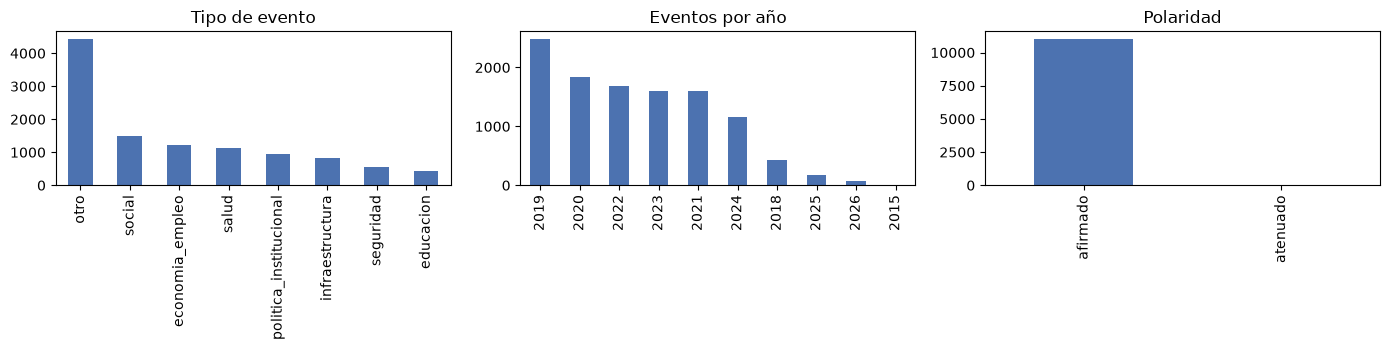

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, clave, titulo in zip(axes, ["por_tipo", "por_ano", "polos"],
                             ["Tipo de evento", "Eventos por año", "Polaridad"]):
    serie = pd.Series(stats[clave]).sort_values(ascending=False)
    serie.plot(kind="bar", ax=ax, color="#4c72b0")
    ax.set_title(titulo)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

In [16]:
pd.DataFrame(stats["disparadores"]).head(12)

,forma,n
0,vamos a,6432
1,voy a,1233
2,va a,987
3,vamos a seguir,630
4,van a,306
5,anuncio,93
6,informo que,91
7,planteamos,84
8,les informo,78
9,anuncio que,76


In [17]:
print("cobertura de slots (eventos):")
pd.Series(stats["cobertura_slots"]).sort_values(ascending=False).to_frame()

cobertura de slots (eventos):


,0
lugar,1481
beneficiario,439
fecha,305
cantidad,242
organizacion,190
monto,111


## 8. Deduplicación: MinHash + LSH

Los presidentes repiten la misma promesa en discursos distintos. Comparar todos los pares es
O(n²). Con MinHash de `k = 96` permutaciones, la probabilidad de que dos conjuntos coincidan en
una posición es su Jaccard y la estimación es insesgada, con error típico $\sqrt{s(1-s)/k}$.
El banding LSH con `b = 12` bandas de `r = 8` filas da

$$P_{\text{colisión}}(s) = 1-(1-s^{r})^{b}$$

y sólo los candidatos se verifican con Jaccard exacto (un falso candidato cuesta tiempo, nunca
un error de agrupación).

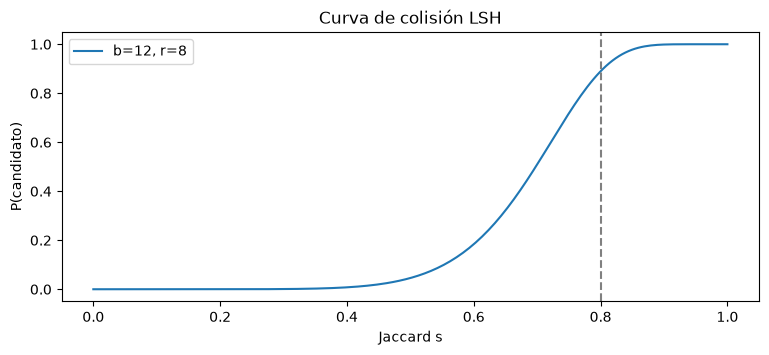

s=0.5: P=0.046 · error MinHash=0.0510
s=0.7: P=0.510 · error MinHash=0.0468
s=0.8: P=0.890 · error MinHash=0.0408
s=0.9: P=0.999 · error MinHash=0.0306
grupos de duplicados en el corpus: 96


In [18]:
r, b = config.LSH_ROWS, config.LSH_BANDS
ss = np.linspace(0, 1, 200)
plt.plot(ss, [collision_probability(s, b, r) for s in ss], label=f"b={b}, r={r}")
plt.axvline(config.DEDUP_JACCARD, ls="--", c="gray")
plt.xlabel("Jaccard s")
plt.ylabel("P(candidato)")
plt.title("Curva de colisión LSH")
plt.legend()
plt.show()

for s in (0.5, 0.7, 0.8, 0.9):
    print(f"s={s}: P={collision_probability(s):.3f} · error MinHash={expected_error(s=s):.4f}")
print("grupos de duplicados en el corpus:", stats["dedup"]["grupos"])

In [19]:
eventos = [json.loads(line) for line in open(config.EVENTS_JSONL, encoding="utf-8")]
dup = pd.DataFrame([{
    "dup_group": e.get("dup_group"), "fecha": e["date"], "hablante": e["speaker"],
    "oración": e["sentence"][:110],
} for e in eventos if e.get("dup_group") is not None])
print(f"{len(dup)} eventos en {dup['dup_group'].nunique()} grupos")
dup.sort_values("dup_group").head(8)

241 eventos en 96 grupos


,dup_group,fecha,hablante,oración
216,0,2024-01-22,Andrés Manuel López Obrador,Vamos a informar sobre la situación de seguridad pública aquí en el estado de Querétaro.
218,0,2024-03-14,Andrés Manuel López Obrador,Vamos a informar sobre la situación de seguridad pública aquí en el estado de Baja Cal...
212,0,2024-01-02,Andrés Manuel López Obrador,"Vamos a informar sobre la situación de seguridad pública aquí, en el estado de Tabasco."
208,0,2023-11-13,Andrés Manuel López Obrador,Vamos a informar sobre la situación de seguridad pública aquí en el estado de Sonora.
165,0,2022-06-10,Andrés Manuel López Obrador,Vamos a informar sobre la situación de seguridad pública aquí en el estado de Oaxaca.
147,0,2022-03-11,Andrés Manuel López Obrador,Vamos a informar sobre la situación de seguridad pública aquí en el estado de Chiapas.
151,0,2022-03-25,Andrés Manuel López Obrador,"Vamos a informar sobre la situación de seguridad pública aquí, en el estado de Morelos."
148,0,2022-03-18,Andrés Manuel López Obrador,Vamos a informar sobre la situación de seguridad pública aquí en el estado de Veracruz.


## 9. Evaluación contra el gold manual

El gold (`ei_scripts/gold/gold_seed.csv`) son **205 oraciones etiquetadas a mano**, en tres
estratos: 125 aleatorias (25 por hablante, miden prevalencia), 40 que el sistema aceptó y 40 que
el sistema tenía con disparador y rechazó. Con muestras pequeñas el intervalo importa más que el
punto, así que se reporta el intervalo de Wilson al 95 %:

$$\frac{\tilde p + \frac{z^2}{2n} \pm z\sqrt{\frac{\tilde p(1-\tilde p)}{n}+\frac{z^2}{4n^2}}}{1+\frac{z^2}{n}}$$

La escalera de ablaciones enciende un componente a la vez, sin umbral de confianza, para medir
cada filtro por separado.

In [20]:
evaluacion = json.loads((config.ARTIFACTS / "eval.json").read_text(encoding="utf-8"))
print("gold:", evaluacion["gold"])
print("prevalencia (aleatorio):", evaluacion["prevalencia_estrato_aleatorio"])
print("kappa:", evaluacion["kappa"])
pd.DataFrame(evaluacion["configuraciones"]).T[["tp", "fp", "fn", "tn", "precision", "recall", "f1"]]

gold: {'n': 205, 'positivas': 38, 'por_estrato': {'aleatorio': 125, 'aceptado': 40, 'rechazado': 40}, 'por_hablante': {'Andrés Manuel López Obrador': 41, 'Javier Milei': 41, 'Nicolás Maduro': 41, 'Pedro Sánchez': 41, 'Sebastián Piñera Echenique': 41}}
prevalencia (aleatorio): {'n': 125, 'positivas': 10, 'prevalencia': 0.08, 'prevalencia_ci': [0.044, 0.141]}
kappa: {'A · autómata vs B · + negación': 0.956, 'A · autómata vs D · + CFG/CYK (completo)': 0.739}


,tp,fp,fn,tn,precision,recall,f1
A · autómata,30,15,8,152,0.667,0.789,0.723
B · + negación,29,13,9,154,0.69,0.763,0.725
C · + slots regex,29,13,9,154,0.69,0.763,0.725
D · + CFG/CYK (completo),25,4,13,163,0.862,0.658,0.746


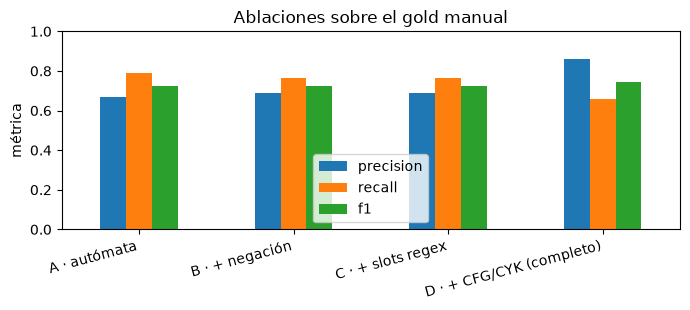

In [21]:
fig, ax = plt.subplots(figsize=(7, 3.2))
abl = pd.DataFrame(evaluacion["configuraciones"]).T
abl[["precision", "recall", "f1"]].astype(float).plot(kind="bar", ax=ax)
ax.set_ylim(0, 1)
ax.set_ylabel("métrica")
ax.set_title("Ablaciones sobre el gold manual")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

In [22]:
pd.DataFrame(evaluacion["barrido_umbral"]).set_index("nivel")[["tp", "fp", "fn", "precision", "recall"]]

,tp,fp,fn,precision,recall
nivel,,,,,
cualquier evidencia,25,4,13,0.862,0.658
acción de contenido,18,3,20,0.857,0.474
+ CYK,17,2,21,0.895,0.447
+ lugar explícito,3,1,35,0.750,0.079
+ fecha / monto / cantidad,1,0,37,1.000,0.026


In [23]:
pd.DataFrame(evaluacion["por_estrato"]).T[["tp", "fp", "fn", "precision", "recall", "f1"]]

,tp,fp,fn,precision,recall,f1
aleatorio,4,0,6,1.0,0.4,0.571
aceptado,21,4,5,0.84,0.808,0.824
rechazado,0,0,2,0.0,0.0,0.0


In [24]:
pd.DataFrame(evaluacion["por_hablante"][evaluacion["config_evaluada"]]).T[
    ["tp", "fp", "fn", "precision", "recall", "f1"]]

,tp,fp,fn,precision,recall,f1
Andrés Manuel López Obrador,8,0,2,1.0,0.8,0.889
Javier Milei,3,0,0,1.0,1.0,1.0
Nicolás Maduro,2,4,4,0.333,0.333,0.333
Pedro Sánchez,8,0,3,1.0,0.727,0.842
Sebastián Piñera Echenique,4,0,4,1.0,0.5,0.667


## 10. Enganche con el módulo de RI

El extractor escribe `doc_id` en el mismo espacio que el índice invertido de RI, así que se
pueden combinar las dos cosas: recuperar con BM25 y quedarse sólo con los discursos que
contienen un evento de un tipo o con un slot concreto.

In [25]:
ix = load_index()
resultados = search_bm25(ix, "becas apoyo jóvenes", k=8)
pd.DataFrame([{k: r[k] for k in ("rank", "doc_id", "speaker", "date", "score")} for r in resultados])

,rank,doc_id,speaker,date,score
0,1,2027,Andrés Manuel López Obrador,2023-12-09,5.194328
1,2,609,Andrés Manuel López Obrador,2020-01-24,5.187205
2,3,673,Andrés Manuel López Obrador,2020-03-06,5.155474
3,4,83,Andrés Manuel López Obrador,2019-02-07,5.142619
4,5,1955,Andrés Manuel López Obrador,2023-09-30,5.140538
5,6,1586,Andrés Manuel López Obrador,2022-08-06,5.129242
6,7,288,Andrés Manuel López Obrador,2019-06-21,5.127254
7,8,879,Andrés Manuel López Obrador,2020-09-20,5.120429


In [26]:
por_doc = {r["doc_id"]: r["events"] for r in by_doc}
filas = []
for r in resultados:
    for ev in por_doc.get(r["doc_id"], []):
        if ev["event_type"] in {"educacion", "social"}:
            filas.append({"doc_id": r["doc_id"], "score_bm25": round(r["score"], 2),
                          "tipo": ev["event_type"], "confianza": ev["confidence"],
                          "oración": ev["sentence"][:95]})
pd.DataFrame(filas).head(10)

,doc_id,score_bm25,tipo,confianza,oración
0,2027,5.19,social,0.61,Vengo a decirles que vamos a continuar apoyando en el tiempo que me queda.
1,2027,5.19,social,0.61,Vamos a seguir apoyando.
2,2027,5.19,social,0.96,Aquí quiero decirles que vamos a construir y a reconstruir 250 mil viviendas en Acapulco.
3,609,5.19,social,0.61,"Vamos a seguir con eso, apoyando a nuestras instituciones que son fundamentales, insti..."
4,673,5.16,social,0.71,"Ahí todavía nos faltan muchos, pero se va a ampliar ese programa de becas para el nive..."
5,673,5.16,educacion,0.71,Por eso vamos a mantener estas becas y cuando ya terminen la prepa y pasen a la univer...
6,673,5.16,educacion,0.61,"También vamos a apoyar mucho en la educación, en la salud, en la educación."
7,673,5.16,educacion,0.71,Yo hablaba yo que en este nuevo gobierno no hemos tenido paros en las escuelas y eso l...
8,83,5.14,educacion,0.71,La educación es un derecho de nuestro pueblo y se va a garantizar a todos.
9,1955,5.14,educacion,0.61,"Vamos a seguir apoyando a maestras, a maestros."


## 11. Limitaciones

* **El gold es de un solo anotador** (semilla): mide acuerdo con un criterio, no con la
  "verdad". Las fronteras son discutibles ("vamos a informar" ¿es promesa?).
* **Los estratos son enriquecidos**: la P/R del conjunto completo no es la del corpus; la
  estimación insesgada es la del estrato aleatorio, y con 125 oraciones su intervalo es ancho.
* **Cobertura**: se detectan anuncios con disparador explícito; las promesas elípticas
  ("y, desde luego, atender a los jóvenes") se pierden. En texto libre la recall del estrato
  aleatorio es baja y está reportada.
* **Los slots son de superficie**: "mil millones" se lee como número, pero no se resuelve a qué
  programa pertenece ni se valida contra el presupuesto.
* **Atribución**: se exige que el hablante o su gobierno sea el sujeto ("va a" sin "vamos/
  gobierno" se descarta). Eso protege la precisión y cuesta recall.
* **Fechas**: el corpus trae discursos con fechas hasta 2026, así que "cumplimiento" sólo puede
  evaluarse de forma ilustrativa.

## 12. Reproducir

```bash
source ../env/bin/activate

python -m ei_scripts.build_events            # corpus -> artifacts/events.jsonl + stats.json
python -m ei_scripts.evaluate --markdown      # métricas + tablas contra el gold

# ablaciones
python -m ei_scripts.build_events --no-cyk --no-slots --tag ablacion
```

Archivos del módulo: `config.py`, `lexicon.py`, `segment.py`, `automaton.py`, `slots.py`,
`grammar.py`, `extract.py`, `dedup.py`, `build_events.py`, `evaluate.py`.
El reporte con fórmulas y resultados completos está en `ei_scripts/doc_ei.md`.